# AI Employment in the USA: Data Visualisation

| | |
|---|---|
| **Module** | Data Visualisation and Communication |
| **Assessment** | CA1 (40%) |
| **Lecturer** | Taufique Ahmed |
| **Student** | Matheus Leandro (2024657) |
| **Programme** | BSc (Hons) in Computing & IT |
| **Submission date** | xxxxx |
| **Video (4 min)** | xxxxx |
| **GitHub repository** | https://github.com/MatheusFerreiraL/dvc-ca1-ai-employment |


## Contents

1. Introduction
2. Data loading and preparation
3. Defining AI-related occupations
4. Visualisations of May 2023 data
5. Challenge: AI employment trends over time
6. Limitations
7. Summary of findings
8. References
9. Appendix: AI use

## 1. Introduction

This notebook uses data visualisation to explore employment in AI, Data Science and Software Development occupations in the United States. The main dataset is the May 2023 "All data" file of the Occupational Employment and Wage Statistics (OEWS) programme of the U.S. Bureau of Labor Statistics (BLS). For the trend analysis, I also used the OEWS national files for May 2019, May 2020, May 2021 and May 2022 (U.S. Bureau of Labor Statistics, 2020b, 2021, 2022, 2023, 2024).

The notebook tries to answer four questions:

1. How many people work in AI-related occupations, and which occupations are the largest?
2. How much are these occupations paid, and how much do wages change between states?
3. In which states are AI-related jobs most common?
4. How did employment and wages in these occupations change from 2019 to 2023?

Section 2 loads and prepares the data, and Section 3 explains which occupations are counted as "AI-related", because the official classification has no AI occupation. Section 4 has five visualisations of the May 2023 data, and Section 5 has three more for the trend over time. For each visualisation, a Markdown cell explains the objective, why that type of chart was chosen and what it shows about AI employment. Section 6 discusses the limitations and Section 7 summarises the findings.

The code uses pandas (McKinney, 2010) for the data and Matplotlib (Hunter, 2007), Seaborn (Waskom, 2021) and Plotly (Plotly Technologies Inc., 2026) for the charts, which are the libraries used in the module. The data files are not included, but the README of the GitHub repository explains where to download them.

In [1]:
# Libraries used in this notebook
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Same look for every static chart
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

## 2. Data loading and preparation

The data comes from the Occupational Employment and Wage Statistics (OEWS) survey of the U.S. Bureau of Labor Statistics (BLS). I used the "All data" file for May 2023 (`all_data_M_2023.xlsx`), which was provided by the lecturer and is also available on the BLS OEWS tables page (U.S. Bureau of Labor Statistics, 2024). The file is not included in this repository, and the README explains how to download it.

### 2.1 Loading the file

The file is read with `pd.read_excel`. It is large (about 80 MB), so this cell takes around one minute to run. Some numeric columns, such as `TOT_EMP` and `A_MEAN`, also contain special codes like `*` and `**` when a value is not available. Because of this, pandas reads those columns as text. Section 2.2 converts them to numbers.

In [2]:
# Read the May 2023 "All data" file (this takes about one minute)
raw_2023 = pd.read_excel("data/oesm23all/all_data_M_2023.xlsx")

# Number of rows and columns
print("Rows:", raw_2023.shape[0])
print("Columns:", raw_2023.shape[1])

Rows: 413327
Columns: 32


In [3]:
raw_2023.head(3)

,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,23.11,37.01,58.4,29050,35660,48060,76980,121470,NaN,NaN
1,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,56.19,81.29,111.36,54550,78330,116880,169090,231620,NaN,NaN
2,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,49.74,79.57,#,46400,66170,103460,165500,#,NaN,NaN


Each row is the estimate for one occupation, in one area, at one industry level. The columns used most in this notebook are:

| Column | Meaning |
|---|---|
| `AREA_TYPE` | 1 = U.S., 2 = state, 3 = U.S. territory, 4 = metropolitan area, 6 = non-metropolitan area |
| `I_GROUP` | Industry level: cross-industry (all industries together), sector, 3-digit to 6-digit NAICS |
| `OCC_CODE`, `OCC_TITLE`, `O_GROUP` | SOC occupation code, title and level (total, major, minor, broad, detailed) |
| `TOT_EMP` | Total employment, rounded to the nearest 10 (self-employed excluded) |
| `A_MEAN`, `A_MEDIAN`, `A_PCT10` … `A_PCT90` | Annual wages: mean, median and percentiles (US dollars) |
| `LOC_QUOTIENT` | Share of the occupation in an area compared with its share in the whole U.S. |

The next cell counts the rows at each level.

In [4]:
# Number of rows at each level of geography, industry and occupation
for col in ["AREA_TYPE", "I_GROUP", "O_GROUP"]:
    print(raw_2023[col].value_counts())
    print()

AREA_TYPE
1    177501
4    149591
6     48559
2     36643
3      1033
Name: count, dtype: int64

I_GROUP
cross-industry               237229
4-digit                       83350
3-digit                       39097
sector                        16376
5-digit                       15518
4-digit, ownership             9856
cross-industry, ownership      5628
3-digit, ownership             4561
6-digit                        1712
Name: count, dtype: int64

O_GROUP
detailed    306185
broad        62131
minor        23374
major        20601
total         1036
Name: count, dtype: int64



The file mixes several levels in the same table. There is one national area, 51 states (including the District of Columbia), 3 territories, 396 metropolitan areas and 136 non-metropolitan areas. Industries and occupations also appear at several levels. If rows from different levels are added together, the same workers are counted more than once. For this reason, Section 2.3 selects one level at a time.

### 2.2 Converting the numeric columns

Some numeric columns use special codes instead of a number. The "Field Descriptions" sheet of the same Excel file explains them:

| Code | Meaning |
|---|---|
| `*` | Wage estimate not available |
| `**` | Employment estimate not available |
| `#` | Wage is $239,200 or more per year ($115.00 or more per hour) |
| `~` | Less than 0.5% of establishments reported the occupation (column `PCT_RPT`, not used here) |

To use these columns in charts, they must be numbers. I used `pd.to_numeric` with `errors="coerce"`. This function was not covered in class. I used it because I could not find a function in the class materials that does the same job in one step. It converts every value that is a valid number and turns the codes into missing values (`NaN`). Missing values are then left out of sums, means and plots. Only the columns used in this notebook are converted.

In [5]:
# Columns with numbers that also contain codes such as *, ** and #
num_cols = ["TOT_EMP", "JOBS_1000", "LOC_QUOTIENT", "A_MEAN",
            "A_PCT10", "A_PCT25", "A_MEDIAN", "A_PCT75", "A_PCT90"]

# Turn each column into numbers; the codes become missing values (NaN)
for col in num_cols:
    raw_2023[col] = pd.to_numeric(raw_2023[col], errors="coerce")

# Number of missing values in each converted column
raw_2023[num_cols].isnull().sum()

TOT_EMP          11598
JOBS_1000       181134
LOC_QUOTIENT    181134
A_MEAN            5352
A_PCT10           5353
A_PCT25           5815
A_MEDIAN          7474
A_PCT75          10606
A_PCT90          17844
dtype: int64

After the conversion, `TOT_EMP` has 11,598 missing values (the `**` code) and `A_MEAN` has 5,352 (the `*` and `#` codes). `JOBS_1000` and `LOC_QUOTIENT` have many more missing values (181,134). Most of them (177,501) are the national rows, which are empty for these two columns because they compare an area with the whole U.S.; the other 3,633 are `**` codes. `A_PCT90` has the most missing wage values (17,844), because the top 10% of wages in well-paid occupations often reaches the $239,200 limit (`#`). This is a limitation, because in those rows the real wage is above the limit, so the highest wages are left out. Section 6 comes back to this point.

### 2.3 Selecting one level of data

As shown in Section 2.1, the same workers appear in several rows. To avoid counting them twice, I made two tables, each with only one level of geography, industry and occupation:

- `national`: the whole U.S. (`AREA_TYPE` 1), all industries together (`I_GROUP` "cross-industry") and single occupations (`O_GROUP` "detailed"). This table is used for most charts.
- `state`: the same, but for each state (`AREA_TYPE` 2). This table is used for the map.

In [6]:
# National level, all industries together, single (detailed) occupations
national = raw_2023[(raw_2023["AREA_TYPE"] == 1) &
                    (raw_2023["I_GROUP"] == "cross-industry") &
                    (raw_2023["O_GROUP"] == "detailed")]

# Each occupation should appear only once
print("Occupations:", len(national))
print("Duplicated occupation codes:", national["OCC_CODE"].duplicated().sum())

Occupations: 831
Duplicated occupation codes: 0


In [7]:
# Check: the detailed occupations should add up to the "All Occupations" total
total_row = raw_2023[(raw_2023["AREA_TYPE"] == 1) &
                     (raw_2023["I_GROUP"] == "cross-industry") &
                     (raw_2023["O_GROUP"] == "total")]

print("All Occupations (BLS total):", total_row["TOT_EMP"].sum())
print("Sum of detailed occupations:", national["TOT_EMP"].sum())

All Occupations (BLS total): 151853870.0
Sum of detailed occupations: 151853170.0


In [8]:
# State level, all industries together, single (detailed) occupations
state = raw_2023[(raw_2023["AREA_TYPE"] == 2) &
                 (raw_2023["I_GROUP"] == "cross-industry") &
                 (raw_2023["O_GROUP"] == "detailed")]

print("Rows:", len(state))
print("States:", len(state["AREA_TITLE"].unique()))

Rows: 35470
States: 51


The `national` table has 831 occupations and no duplicated codes. Its employment adds up to 151,853,170, which is only 700 less than the "All Occupations" total given by BLS (151,853,870). The small gap comes from rounding, because BLS rounds each employment figure to the nearest 10. This confirms that the filter does not count workers twice. The `state` table has 35,470 rows for 51 areas (the 50 states and the District of Columbia).

## 3. Defining AI-related occupations

The OEWS data uses the 2018 Standard Occupational Classification (SOC). This system has no occupation called "AI engineer" or "machine learning engineer", so people who work on AI are counted inside other occupations. In the full list of SOC definitions, the words "artificial intelligence" do not appear at all, and "machine learning" appears only once, in the definition of Data Scientists (U.S. Bureau of Labor Statistics, 2020a).

For this reason, I defined "AI employment" as a group of eight SOC occupations. I split them into the three areas named in the brief: AI, Data Science and Software Development. Each choice is based on the official SOC definition of the occupation.

| Group | SOC code | Occupation | Reason for including it |
|---|---|---|---|
| AI research | 15-1221 | Computer and Information Research Scientists | The closest occupation to AI research: they do basic research in computer science and design new solutions for hardware and software problems |
| Data Science | 15-2051 | Data Scientists | The only definition that names machine learning and natural language processing |
| Data Science | 15-2041 | Statisticians | Develop and apply statistical methods to analyse data; machine learning is based on these methods |
| Data Science | 15-2031 | Operations Research Analysts | Use mathematical models and data to support decisions, and may develop decision support software |
| Software Development | 15-1252 | Software Developers | Design and build software, which includes the systems where AI models are used |
| Software Development | 15-1251 | Computer Programmers | Write and test the code of computer applications |
| Software Development | 15-1253 | Software Quality Assurance Analysts and Testers | Test software and record its defects, so they work on the same products as developers |
| Software Development | 15-1254 | Web Developers | Build websites and web applications, including the databases and interfaces behind them |

This definition has a limitation. Not every worker in these occupations works on AI, and some AI workers are counted in other occupations (for example, "Computer Occupations, All Other"). The group is therefore a proxy for AI employment, not an exact count. Section 6 discusses this again.

To mark the eight occupations, I wrote a dictionary with the SOC code as the key and the group as the value. Then I used `.map()` to add a `GROUP` column to a copy of the `national` table. Occupations that are not in the dictionary get a missing value, so `.dropna(subset=["GROUP"])` removes them and leaves only the eight AI-related occupations. The `subset` option makes `dropna` look only at the `GROUP` column, because other columns (for example `A_PCT90`) also have missing values.

In [9]:
# The eight AI-related occupations: SOC code and group
ai_groups = {
    "15-1221": "AI research",
    "15-2051": "Data Science",
    "15-2041": "Data Science",
    "15-2031": "Data Science",
    "15-1252": "Software Development",
    "15-1251": "Software Development",
    "15-1253": "Software Development",
    "15-1254": "Software Development"
}

# Add the group of each occupation (other occupations get NaN)
ai_jobs = national.copy()
ai_jobs["GROUP"] = ai_jobs["OCC_CODE"].map(ai_groups)

# Keep only the eight AI-related occupations
ai_jobs = ai_jobs.dropna(subset=["GROUP"])

# Main columns, from the largest employment to the smallest
ai_jobs[["GROUP", "OCC_CODE", "OCC_TITLE", "TOT_EMP", "A_MEAN", "A_MEDIAN"]].sort_values("TOT_EMP", ascending=False)

,GROUP,OCC_CODE,OCC_TITLE,TOT_EMP,A_MEAN,A_MEDIAN
149,Software Development,15-1252,Software Developers,1656880.0,138110.0,132270.0
150,Software Development,15-1253,Software Quality Assurance Analysts and Testers,203040.0,108460.0,101800.0
165,Data Science,15-2051,Data Scientists,192710.0,119040.0,108020.0
148,Software Development,15-1251,Computer Programmers,120370.0,107750.0,99700.0
161,Data Science,15-2031,Operations Research Analysts,117880.0,95600.0,83640.0
151,Software Development,15-1254,Web Developers,85350.0,95570.0,84960.0
138,AI research,15-1221,Computer and Information Research Scientists,35210.0,157160.0,145080.0
163,Data Science,15-2041,Statisticians,29950.0,109190.0,104110.0


In [10]:
# Total employment of each group
group_emp = ai_jobs.groupby("GROUP")["TOT_EMP"].sum()
print(group_emp)
print()

# AI-related employment compared with all occupations in the U.S.
print("AI-related employment:", ai_jobs["TOT_EMP"].sum())
print("Share of all U.S. employment (%):", round(ai_jobs["TOT_EMP"].sum() / national["TOT_EMP"].sum() * 100, 2))

GROUP
AI research               35210.0
Data Science             340540.0
Software Development    2065640.0
Name: TOT_EMP, dtype: float64

AI-related employment: 2441390.0
Share of all U.S. employment (%): 1.61


The eight occupations employ 2,441,390 people, which is 1.61% of all employment in the U.S. in May 2023. Software Development is by far the largest group, with 2,065,640 workers (about 85% of the total), and Software Developers alone account for 1,656,880. Data Science has 340,540 workers, and AI research is the smallest group, with only 35,210. However, AI research has the highest mean annual wage of the eight occupations ($157,160). Because of this difference in size, the AI research group would be almost invisible next to Software Developers on one common scale, so the scale of each chart in Section 4 has to be chosen with care.

## 4. Visualisations of May 2023 data

This section uses the May 2023 data only. Visualisations 1 and 4 use the `national` table, and Visualisations 2, 3 and 5 use the `state` table, because they compare the states. Each group has the same colour in every chart: orange for AI research, green for Data Science and purple for Software Development.

### 4.1 Visualisation 1: Horizontal bar chart of employment by occupation

This first chart compares the size of the eight AI-related occupations. The same three colours are used for the groups in every chart of this notebook, so the reader can follow each group from one chart to the next.

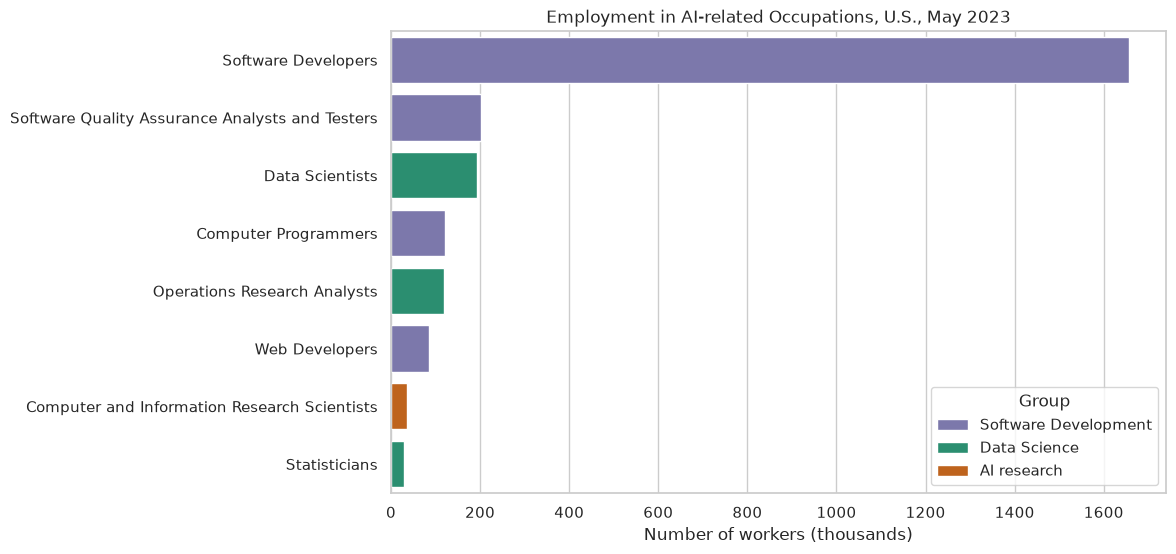

In [11]:
# One colour per group, used again in the next charts
group_colours = {
    "AI research": "#d95f02",
    "Data Science": "#1b9e77",
    "Software Development": "#7570b3"
}

# Employment in thousands, so the axis numbers are short
ai_jobs["EMP_THOUSANDS"] = ai_jobs["TOT_EMP"] / 1000

# Largest occupation at the top
emp_sorted = ai_jobs.sort_values("TOT_EMP", ascending=False)

sns.barplot(data=emp_sorted, x="EMP_THOUSANDS", y="OCC_TITLE", hue="GROUP", palette=group_colours)
plt.title("Employment in AI-related Occupations, U.S., May 2023")
plt.xlabel("Number of workers (thousands)")
plt.ylabel("")
plt.legend(title="Group")
plt.show()

- **Objective:** To compare how many people work in each of the eight AI-related occupations, and to see which group is the largest.
- **Why this plot:** The occupation is a categorical variable and employment is a numerical value, so a bar chart is the natural way to compare them. I used horizontal bars because the occupation names are long and would overlap on a vertical x-axis. The bars are sorted from the largest to the smallest, and the colour shows the group. I used `sns.barplot` instead of `sns.countplot` (used in the class tutorial: Ahmed, 2026a) because the data already has one total per occupation, so nothing needs to be counted. I kept a linear scale: a logarithmic scale would show the small bars better, but it would hide how big the real differences are.
- **Learning:** Software Developers are by far the largest occupation, with 1,656,880 workers. This is about 68% of all AI-related employment and more than twice the other seven occupations together (784,510). Software Quality Assurance Analysts and Testers (203,040) and Data Scientists (192,710) come next, with very similar sizes. The occupations closest to AI research and statistics are the smallest: Computer and Information Research Scientists have 35,210 workers and Statisticians 29,950. This means that in 2023 most AI-related jobs were about building and testing software, and only a small number were in research.

### 4.2 Visualisation 2: Box plot of mean annual wage across states

The OEWS file does not give the wage of each worker. It only gives summary values (mean and percentiles) for each occupation in each area. For this reason, this chart uses the `state` table: each value is the mean annual wage of one occupation in one state, so for each occupation there are up to 51 values (50 states and the District of Columbia).

In [12]:
# Keep the eight AI-related occupations in the state table and add their group
ai_state = state.copy()
ai_state["GROUP"] = ai_state["OCC_CODE"].map(ai_groups)
ai_state = ai_state.dropna(subset=["GROUP"])

# Mean annual wage in thousands of dollars, so the axis numbers are short
ai_state["A_MEAN_THOUSANDS"] = ai_state["A_MEAN"] / 1000

# Number of states with a published mean wage and summary of the values
ai_state.groupby("OCC_TITLE")["A_MEAN"].describe().round(0).sort_values("50%", ascending=False)

,count,mean,std,min,25%,50%,75%,max
OCC_TITLE,,,,,,,,
Computer and Information Research Scientists,42.0,133538.0,27625.0,88770.0,112440.0,131240.0,145800.0,202910.0
Software Developers,51.0,123645.0,17487.0,88130.0,110865.0,123700.0,132570.0,173780.0
Data Scientists,51.0,110043.0,17137.0,72220.0,97430.0,107000.0,125215.0,148730.0
Computer Programmers,49.0,98419.0,15549.0,65320.0,90890.0,97480.0,103460.0,158520.0
Software Quality Assurance Analysts and Testers,49.0,96709.0,17001.0,63530.0,85160.0,96610.0,112880.0,132750.0
Statisticians,49.0,97084.0,18608.0,60860.0,84000.0,95510.0,108720.0,140860.0
Operations Research Analysts,49.0,91483.0,13203.0,63640.0,82110.0,90540.0,100240.0,121120.0
Web Developers,49.0,85146.0,17126.0,48730.0,74620.0,83470.0,95810.0,123640.0


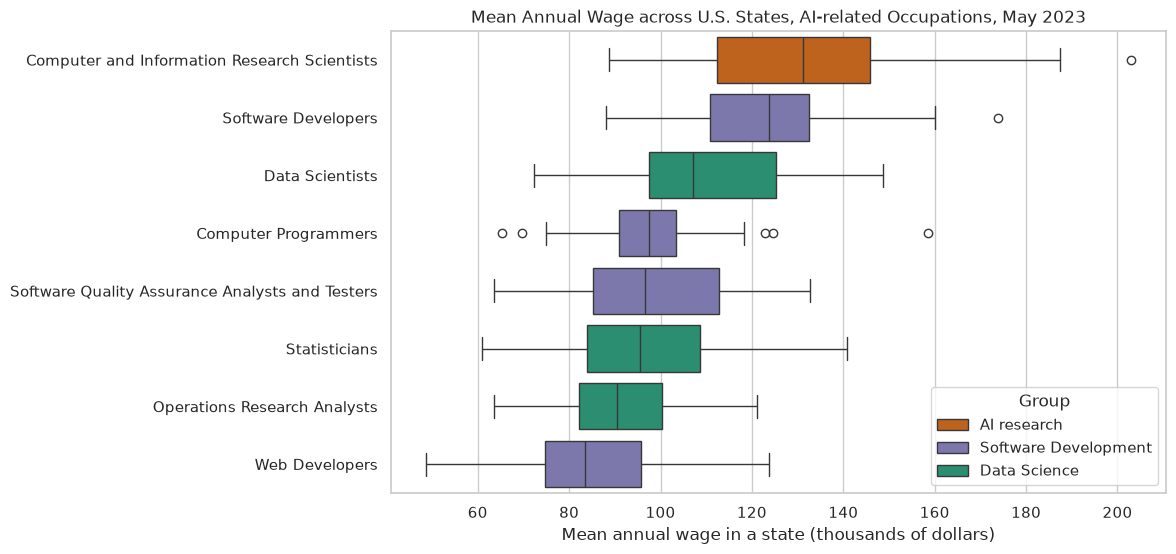

In [13]:
# Occupations ordered by their median state wage, from highest to lowest
wage_order = ai_state.groupby("OCC_TITLE")["A_MEAN"].median().sort_values(ascending=False).index

sns.boxplot(data=ai_state, x="A_MEAN_THOUSANDS", y="OCC_TITLE", hue="GROUP",
            order=wage_order, palette=group_colours, dodge=False)
plt.title("Mean Annual Wage across U.S. States, AI-related Occupations, May 2023")
plt.xlabel("Mean annual wage in a state (thousands of dollars)")
plt.ylabel("")
plt.legend(title="Group")
plt.show()

In [14]:
# Rows with a published mean wage, from the lowest to the highest wage
wage_known = ai_state.dropna(subset=["A_MEAN"]).sort_values("A_MEAN")

# First row of each occupation = lowest state; last row = highest state
lowest = wage_known.groupby("OCC_TITLE").first()
highest = wage_known.groupby("OCC_TITLE").last()

state_range = pd.DataFrame({
    "Lowest state": lowest["AREA_TITLE"],
    "Lowest wage": lowest["A_MEAN"],
    "Highest state": highest["AREA_TITLE"],
    "Highest wage": highest["A_MEAN"]
})
state_range["Difference"] = state_range["Highest wage"] - state_range["Lowest wage"]
state_range.sort_values("Highest wage", ascending=False)

,Lowest state,Lowest wage,Highest state,Highest wage,Difference
OCC_TITLE,,,,,
Computer and Information Research Scientists,Indiana,88770.0,Washington,202910.0,114140.0
Software Developers,Arkansas,88130.0,California,173780.0,85650.0
Computer Programmers,South Dakota,65320.0,Washington,158520.0,93200.0
Data Scientists,Mississippi,72220.0,Washington,148730.0,76510.0
Statisticians,Mississippi,60860.0,New York,140860.0,80000.0
Software Quality Assurance Analysts and Testers,West Virginia,63530.0,California,132750.0,69220.0
Web Developers,Arkansas,48730.0,District of Columbia,123640.0,74910.0
Operations Research Analysts,Missouri,63640.0,Virginia,121120.0,57480.0


- **Objective:** To investigate how much the wage of each AI-related occupation changes from one state to another, and to compare the typical wage of the eight occupations.
- **Why this plot:** The wage is a continuous numerical variable and the occupation is categorical. A box plot shows the median, the middle 50% of the states (the box), the range and the outliers of each occupation in one chart, so the eight distributions can be compared side by side. This follows the "Fare by Class" box plot of the class tutorial (Ahmed, 2026a). A bar chart of the national mean would show only one number per occupation and would hide the differences between states.
- **Learning:** Computer and Information Research Scientists have the highest median state wage ($131,240), followed by Software Developers ($123,700) and Data Scientists ($107,000). Web Developers have the lowest median ($83,470). The order is similar to the national means in Section 3, so the most research-based jobs are also the best paid. The spread inside each occupation is wide. For Software Developers, the mean wage goes from $88,130 in Arkansas to $173,780 in California, a difference of $85,650. This is larger than the gap between the highest and the lowest median of the chart ($47,770), so the state where a person works can change the wage more than the choice between these occupations. Washington and California have the highest wage for five of the eight occupations, while the lowest values are mostly in southern and central states such as Arkansas and Mississippi. The national means in Section 3 are higher than the state medians (for example $157,160 against $131,240 for research scientists). The national mean is weighted by the number of workers, while the box plot counts each state once, so this gap suggests that the states with many workers pay more than the average state.

In a box plot every state counts the same, so a small state has the same weight as California. Also, wages are not published for some states (for example, only 42 states have a value for Computer and Information Research Scientists), because BLS hides estimates that are not reliable or that are too few to keep confidential.

### 4.3 Visualisation 3: Scatter plot of Software Developer jobs and wages by state

Visualisation 2 suggested that states with many AI-related workers also pay more. This chart tests that idea for Software Developers, the largest of the eight occupations (Visualisation 1) and the only one with values for all 51 states. Each point is one state. `JOBS_1000` is the number of Software Developer jobs for every 1,000 jobs in the state, so states of different sizes can be compared.

In [15]:
# Software Developers in each state
dev_state = ai_state[ai_state["OCC_CODE"] == "15-1252"]

# States with values for both variables
print("States:", dev_state[["JOBS_1000", "A_MEAN"]].dropna().shape[0])

# Correlation between the share of jobs and the mean wage
print("Correlation:", round(dev_state["JOBS_1000"].corr(dev_state["A_MEAN"]), 2))

States: 51
Correlation: 0.61


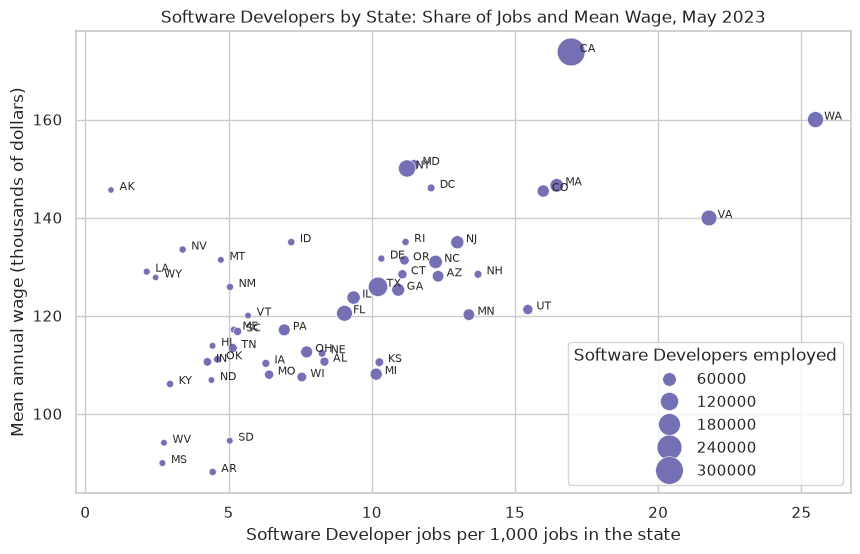

In [16]:
sns.scatterplot(data=dev_state, x="JOBS_1000", y="A_MEAN_THOUSANDS", size="TOT_EMP",
                sizes=(20, 400), color=group_colours["Software Development"])

# Write the state code next to each point
for i, row in dev_state.iterrows():
    plt.text(row["JOBS_1000"] + 0.3, row["A_MEAN_THOUSANDS"], row["PRIM_STATE"], fontsize=8)

plt.title("Software Developers by State: Share of Jobs and Mean Wage, May 2023")
plt.xlabel("Software Developer jobs per 1,000 jobs in the state")
plt.ylabel("Mean annual wage (thousands of dollars)")
plt.legend(title="Software Developers employed")
plt.show()

In [17]:
# States with the highest and the lowest share of Software Developer jobs
cols = ["AREA_TITLE", "JOBS_1000", "A_MEAN", "TOT_EMP"]
print(dev_state.sort_values("JOBS_1000", ascending=False)[cols].head(5))
print()
print(dev_state.sort_values("JOBS_1000")[cols].head(5))

           AREA_TITLE  JOBS_1000    A_MEAN   TOT_EMP
181589     Washington     25.492  159990.0   89110.0
181588       Virginia     21.773  139920.0   86680.0
181546     California     16.961  173780.0  304390.0
181563  Massachusetts     16.458  146580.0   59960.0
181547       Colorado     15.985  145420.0   45270.0

           AREA_TITLE  JOBS_1000    A_MEAN  TOT_EMP
181543         Alaska      0.893  145630.0    280.0
181560      Louisiana      2.140  128980.0   3960.0
181592        Wyoming      2.453  127790.0    670.0
181566    Mississippi      2.689   89940.0   3090.0
181590  West Virginia      2.742   94080.0   1890.0


- **Objective:** To investigate the relationship between how common Software Developer jobs are in a state and how much they are paid there.
- **Why this plot:** Both variables are numerical and continuous, and a scatter plot is the standard chart to show the relationship between two numerical variables, as in the "Age vs Fare" example of the class tutorial (Ahmed, 2026a). The size of each point shows the number of Software Developers, so large states such as California are easy to find. I added the state codes with `plt.text` inside a `for` loop over the rows (`iterrows`), because without them the reader could not tell which point is which state. The correlation coefficient from `.corr()` gives one number for the strength of the relationship.
- **Learning:** There is a moderate positive relationship (correlation 0.61): states where Software Developers are a larger share of jobs usually pay them more. Washington has the highest share (25.5 jobs per 1,000) and a mean wage of $159,990, and Virginia, California, Massachusetts and Colorado follow, all with mean wages above $139,000. California has the largest point (304,390 developers) and the highest wage ($173,780). However, the relationship is not perfect. Alaska has the lowest share (0.9 per 1,000) but a high mean wage ($145,630), and Louisiana and Wyoming are similar cases. This supports the idea from Visualisation 2 that the states with many workers pay more, but a scatter plot shows an association, not a cause: other factors that are not in this dataset, such as the cost of living or the kind of employers in each state, can also affect wages.

### 4.4 Visualisation 4: Pie charts of the share of jobs and wages by group

This visualisation compares two shares of the same three groups: the share of AI-related jobs and the share of the money paid in wages. The total annual wages of an occupation are its employment multiplied by its mean annual wage (`TOT_EMP` × `A_MEAN`), because a mean is the total divided by the number of workers.

In [18]:
# Total annual wages paid in each occupation
ai_jobs["TOTAL_WAGES"] = ai_jobs["TOT_EMP"] * ai_jobs["A_MEAN"]

# Jobs and wages of each group
group_totals = ai_jobs.groupby("GROUP")[["TOT_EMP", "TOTAL_WAGES"]].sum()

# Share of each group (%)
group_share = group_totals / group_totals.sum() * 100
print(group_share.round(1))
print()
print("Total annual wages (billion $):", round(ai_jobs["TOTAL_WAGES"].sum() / 1e9, 1))

                      TOT_EMP  TOTAL_WAGES
GROUP                                     
AI research               1.4          1.8
Data Science             13.9         11.9
Software Development     84.6         86.3

Total annual wages (billion $): 315.0


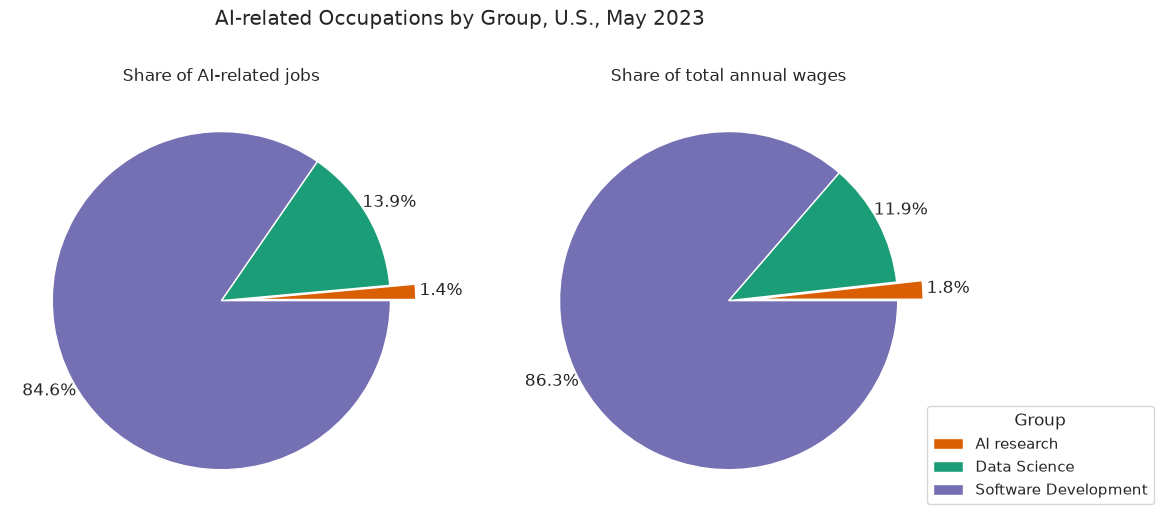

In [19]:
# Same colour for each group as in the other charts
pie_colours = [group_colours[g] for g in group_totals.index]

# Move the small "AI research" slice out so it can be seen
# (the percentages are written outside the pie, because the slice is too thin for text)
explode = (0.15, 0, 0)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.pie(group_totals["TOT_EMP"], colors=pie_colours,
        explode=explode, autopct="%1.1f%%", startangle=0,
        pctdistance=1.15)
plt.title("Share of AI-related jobs")

plt.subplot(1, 2, 2)
plt.pie(group_totals["TOTAL_WAGES"], colors=pie_colours,
        explode=explode, autopct="%1.1f%%", startangle=0,
        pctdistance=1.15)
plt.title("Share of total annual wages")

# One legend for both pies, placed at the bottom right of the second pie
plt.legend(group_totals.index, title="Group", loc="lower left", bbox_to_anchor=(0.95, 0))

plt.suptitle("AI-related Occupations by Group, U.S., May 2023")
plt.show()

- **Objective:** To show how the AI-related workforce is divided between the three groups, and to compare this with how the wages are divided.
- **Why this plot:** Each pie shows a part-to-whole relationship: the three groups together make 100% of AI-related jobs (left) or wages (right). A pie chart works here because there are only three categories and the differences between them are large, and it is the chart used in the class tutorial for proportions (Ahmed, 2026a). With many slices or very similar values a bar chart would be clearer. Putting the two pies side by side with `plt.subplot` makes the comparison direct, and the small AI research slice is pulled out (`explode`) so it is not lost. The percentages are written outside the pies and one legend is used for both, because the AI research slice is too thin to hold any text.
- **Learning:** Software Development is 84.6% of AI-related jobs and 86.3% of the wages, so it dominates both. The two smaller groups move in opposite directions. AI research has 1.4% of the jobs but 1.8% of the wages, because it has the highest mean wage (Section 3). Data Science has 13.9% of the jobs but only 11.9% of the wages: Data Scientists are well paid, but the group also includes Operations Research Analysts and Statisticians, whose median state wages were among the lowest in Visualisation 2. So when wages are counted instead of jobs, AI research becomes a little more important, but it is still a very small part of the AI-related workforce.

### 4.5 Visualisation 5: Choropleth map of AI-related jobs per 1,000 jobs by state

This map shows where AI-related jobs are most common. For each state, the value is the sum of `JOBS_1000` for the eight occupations. The values can be added because they all use the same base (the total number of jobs in that state), so the sum is the number of AI-related jobs for every 1,000 jobs.

BLS does not publish every occupation in every state. When an occupation is missing, its jobs are not in the sum, so the value of that state is a minimum. The number of published occupations is shown when the mouse is over a state.

In [20]:
# Sum of the eight occupations in each state
state_map = ai_state.groupby(["AREA_TITLE", "PRIM_STATE"])[["JOBS_1000", "TOT_EMP"]].sum().reset_index()

# Number of the eight occupations with a published value in each state
state_map["OCCUPATIONS"] = ai_state.groupby(["AREA_TITLE", "PRIM_STATE"])["JOBS_1000"].count().values

# National value, to compare with the states
national_rate = ai_jobs["TOT_EMP"].sum() / national["TOT_EMP"].sum() * 1000
print("U.S. AI-related jobs per 1,000 jobs:", round(national_rate, 1))
print("States above the U.S. value:", (state_map["JOBS_1000"] > national_rate).sum())
print("States with fewer than 8 published occupations:", (state_map["OCCUPATIONS"] < 8).sum())
print()
print(state_map.sort_values("JOBS_1000", ascending=False).head(5))
print()
print(state_map.sort_values("JOBS_1000").head(5))

U.S. AI-related jobs per 1,000 jobs: 16.1
States above the U.S. value: 16
States with fewer than 8 published occupations: 18

              AREA_TITLE PRIM_STATE  JOBS_1000   TOT_EMP  OCCUPATIONS
47            Washington         WA     35.066  122580.0            8
46              Virginia         VA     29.854  118840.0            8
8   District of Columbia         DC     24.988   17530.0            8
4             California         CA     24.086  432280.0            8
21         Massachusetts         MA     23.008   83830.0            6

       AREA_TITLE PRIM_STATE  JOBS_1000  TOT_EMP  OCCUPATIONS
50        Wyoming         WY      2.723    750.0            3
1          Alaska         AK      3.531   1110.0            6
24    Mississippi         MS      3.920   4500.0            7
18      Louisiana         LA      4.274   7910.0            8
48  West Virginia         WV      4.845   3340.0            8


In [21]:
fig_map = px.choropleth(
    state_map,
    locations="PRIM_STATE",
    locationmode="USA-states",
    color="JOBS_1000",
    scope="usa",
    hover_name="AREA_TITLE",
    hover_data=["TOT_EMP", "OCCUPATIONS"],
    color_continuous_scale="Purples",
    labels={"JOBS_1000": "Jobs per 1,000", "TOT_EMP": "AI-related workers",
            "OCCUPATIONS": "Occupations published (of 8)", "PRIM_STATE": "State"},
    title="AI-related Jobs per 1,000 Jobs by State, May 2023"
)
fig_map.show()

Interactive Plotly charts are shown only when the notebook is opened in a program that supports Plotly (for example JupyterLab). The next cell shows the same map as a fixed image, so it can also be seen on GitHub or in other viewers. It uses the `kaleido` package, which Plotly needs to save a chart as an image.

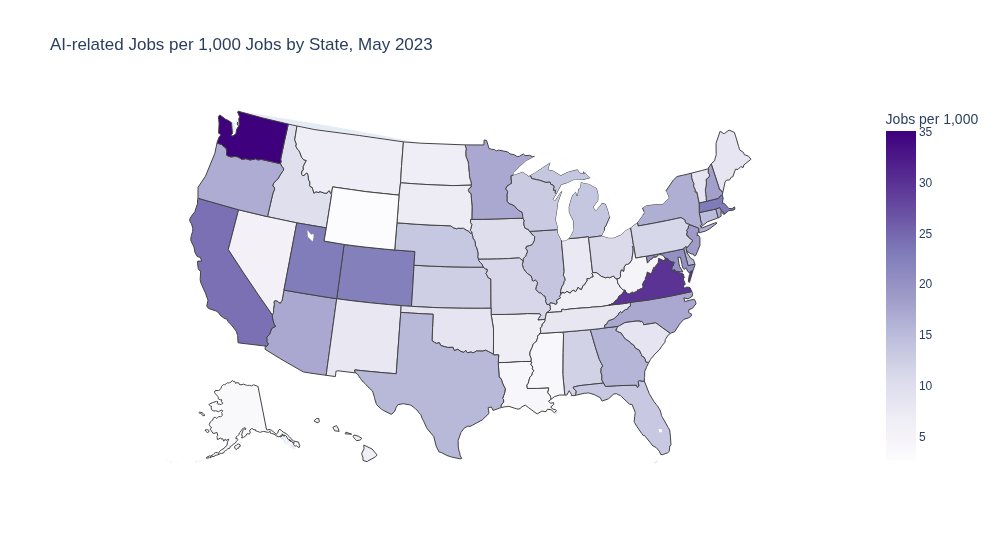

In [22]:
# Same map as a fixed PNG image
fig_map.show(renderer="png", width=1000, height=550)

- **Objective:** To compare the states and find where AI-related jobs make up the largest part of the economy.
- **Why this plot:** The data is geographical, with one value per state, and a choropleth map shows the pattern across the country in one view: neighbouring states and regions can be compared, which is hard in a list of 51 bars. A rate (jobs per 1,000) is used instead of the number of workers, because a map of totals would mostly show which states are the biggest. A single-colour scale (darker = more jobs) suits a numerical variable that goes from low to high. I used Plotly, as in the class on interactive visualisation (Ahmed, 2026c), so the reader can see the exact values of each state with the mouse. `px.choropleth` was not used in class, but it follows the same `plotly.express` pattern as `px.scatter` and `px.bar`.
- **Learning:** In the whole U.S. there are 16.1 AI-related jobs for every 1,000 jobs, and only 16 of the 51 areas are above this value. Washington has the highest value (35.1), followed by Virginia (29.9), the District of Columbia (25.0), California (24.1) and Massachusetts (23.0). The lowest values are in Wyoming (2.7), Alaska (3.5), Mississippi (3.9), Louisiana (4.3) and West Virginia (4.8). The map shows that AI-related work is concentrated on the west coast, in Colorado and Utah, in the north-east and around Washington, D.C. (the District of Columbia is too small to see on the map, but its value appears in the table above). Most of the central and southern states are light. These are also many of the states with the highest wages in Visualisations 2 and 3. One caution: 18 states have fewer than eight published occupations (Wyoming has only three), so their real values are probably a little higher than the map shows. Massachusetts is one of them, with six occupations, and it is still in the top five.

## 5. Challenge: AI employment trends over time

This section uses four more datasets from the BLS OEWS tables page: the national files for May 2019, May 2020, May 2021 and May 2022. Together with May 2023, they give five years of data. I used the "National" files and not the "All data" files, because only the national rows are needed to follow the trend, and these files are much smaller (about 250 KB instead of 80 MB). The 2023 values come from the `national` table of Section 2.3, which has the same national, cross-industry, detailed rows.

All five years use the 2018 SOC system, so the occupation codes are the same, with one exception that is explained in Section 5.2.

### 5.1 Loading the earlier years

In [23]:
# National files of the four earlier years
files = {
    2019: "data/oesm19nat/national_M2019_dl.xlsx",
    2020: "data/oesm20nat/national_M2020_dl.xlsx",
    2021: "data/oesm21nat/national_M2021_dl.xlsx",
    2022: "data/oesm22nat/national_M2022_dl.xlsx"
}

years = []
for year in files:
    df = pd.read_excel(files[year])

    # The 2019 file has lower-case column names, the other years upper-case
    df.columns = df.columns.str.upper()

    # Single (detailed) occupations only, as in Section 2.3
    df = df[df["O_GROUP"] == "detailed"].copy()
    df["YEAR"] = year
    years.append(df)

# May 2023: the national table already prepared in Section 2.3
national_2023 = national.copy()
national_2023["YEAR"] = 2023
years.append(national_2023)

# One table with the five years
all_years = pd.concat(years)

# Same conversion as in Section 2.2: codes such as * and ** become NaN
for col in ["TOT_EMP", "A_MEAN"]:
    all_years[col] = pd.to_numeric(all_years[col], errors="coerce")

# Check: number of occupations and total employment of each year
all_years.groupby("YEAR")["TOT_EMP"].agg(["count", "sum"])

,count,sum
YEAR,,
2019,789,146873470.0
2020,788,139096790.0
2021,831,140885570.0
2022,830,147884760.0
2023,831,151853170.0


Each year has between 788 and 831 detailed occupations. The 2019 and 2020 files have fewer, partly because some occupations were still merged in those years (Section 5.2). Total employment fell from 146.9 million in May 2019 to 139.1 million in May 2020, most likely because of the COVID-19 pandemic, and it was above the 2019 level again in May 2022 (147.9 million). For this reason, the trend charts below always compare the AI-related groups with all occupations.

### 5.2 Matching the occupation codes across years

The 2018 SOC system was introduced in OEWS over a few years. The May 2019 and May 2020 estimates mix the 2010 and 2018 SOC systems, and May 2021 was the first year based fully on the 2018 SOC (U.S. Bureau of Labor Statistics, no date). In the May 2019 and May 2020 files, some occupations are still combined in one code, as their titles show:

| Code in 2019 and 2020 | Title in the file | Codes from 2021 |
|---|---|---|
| 15-1256 | Software Developers and Software Quality Assurance Analysts and Testers | 15-1252 and 15-1253 |
| 15-1257 | Web Developers and Digital Interface Designers | 15-1254 and 15-1255 |
| 15-2098 | Data Scientists and Mathematical Science Occupations, All Other | 15-2051 and 15-2099 |

The combined codes cannot be split, so I compared the same jobs in every year by using slightly wider groups. Software Development also includes Web and Digital Interface Designers (15-1255), and Data Science also includes Mathematical Science Occupations, All Other (15-2099), in all five years. The dictionary `trend_groups` has the old and the new codes. Because a code exists either in 2019–2020 or in 2021–2023, never in both, one dictionary works for every year and no worker is counted twice.

These wider groups are larger than the groups of Section 3. In 2023, Software Development has 2,176,700 workers instead of 2,065,640 (111,060 designers more) and Data Science has 344,860 instead of 340,540. The output below confirms that seven codes are found in 2019 and 2020 and ten codes from 2021, with no missing values. Visualisation 8 then uses the exact eight occupations for the years where they all exist.

In [24]:
# Occupation codes of each group in all five years
# (15-1256, 15-1257 and 15-2098 exist only in 2019 and 2020)
trend_groups = {
    "15-1221": "AI research",
    "15-2051": "Data Science",
    "15-2099": "Data Science",
    "15-2098": "Data Science",
    "15-2041": "Data Science",
    "15-2031": "Data Science",
    "15-1251": "Software Development",
    "15-1252": "Software Development",
    "15-1253": "Software Development",
    "15-1254": "Software Development",
    "15-1255": "Software Development",
    "15-1256": "Software Development",
    "15-1257": "Software Development"
}

trend = all_years.copy()
trend["GROUP"] = trend["OCC_CODE"].map(trend_groups)
trend = trend.dropna(subset=["GROUP"])

# Number of codes found in each year and missing values
print(trend.groupby("YEAR")["OCC_CODE"].count())
print("Missing employment:", trend["TOT_EMP"].isnull().sum())
print("Missing mean wage:", trend["A_MEAN"].isnull().sum())

YEAR
2019     7
2020     7
2021    10
2022    10
2023    10
Name: OCC_CODE, dtype: int64
Missing employment: 0
Missing mean wage: 0


In [25]:
# Total wages of each occupation, as in Visualisation 4
trend["TOTAL_WAGES"] = trend["TOT_EMP"] * trend["A_MEAN"]

# Jobs and wages of each group in each year
group_year = trend.groupby(["YEAR", "GROUP"])[["TOT_EMP", "TOTAL_WAGES"]].sum().reset_index()

# Mean wage of the group = total wages / number of workers
group_year["MEAN_WAGE"] = group_year["TOTAL_WAGES"] / group_year["TOT_EMP"]

# Employment of each group, one column per group
group_year.pivot(index="YEAR", columns="GROUP", values="TOT_EMP")

GROUP,AI research,Data Science,Software Development
YEAR,,,
2019,30780.0,169580.0,1754750.0
2020,30220.0,194760.0,1811160.0
2021,30840.0,240020.0,1874110.0
2022,33780.0,299330.0,2049920.0
2023,35210.0,344860.0,2176700.0


### 5.3 Visualisation 6: Line chart of employment growth since 2019

The three groups have very different sizes (in 2023, 35,210 workers in AI research against 2,176,700 in Software Development), so on a normal axis the small groups would look flat. For this reason, the chart shows an index: the employment of each year divided by the employment of 2019, multiplied by 100. A value of 100 means the same as in 2019, and 120 means 20% more workers than in 2019.

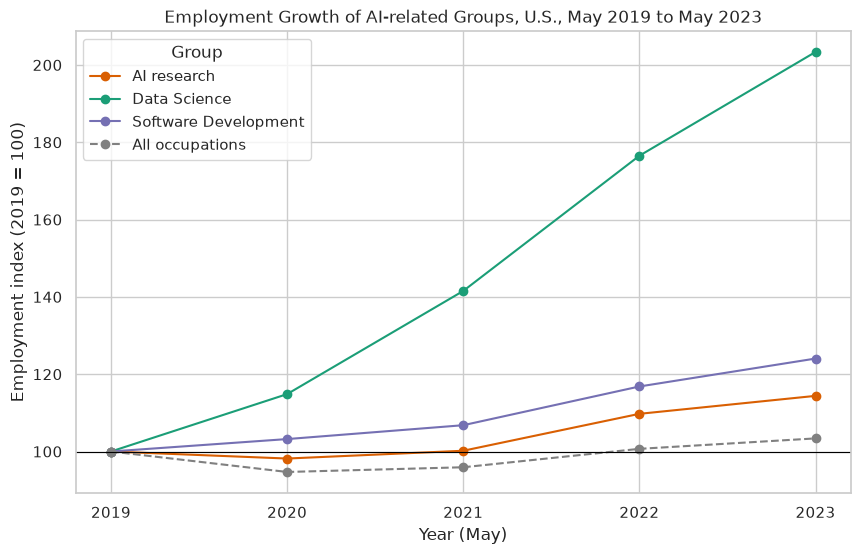

GROUP  AI research  Data Science  Software Development
YEAR                                                  
2019         100.0         100.0                 100.0
2020          98.2         114.8                 103.2
2021         100.2         141.5                 106.8
2022         109.7         176.5                 116.8
2023         114.4         203.4                 124.0

YEAR
2019    100.0
2020     94.7
2021     95.9
2022    100.7
2023    103.4
Name: TOT_EMP, dtype: float64


In [26]:
# Employment of each group in 2019 (the base year)
base_2019 = group_year[group_year["YEAR"] == 2019].set_index("GROUP")["TOT_EMP"]

# Index: employment of the year / employment in 2019 x 100
group_year["EMP_INDEX"] = group_year["TOT_EMP"] / group_year["GROUP"].map(base_2019) * 100

# Same index for all occupations in the U.S., for comparison
total_year = all_years.groupby("YEAR")["TOT_EMP"].sum()
total_index = total_year / total_year[2019] * 100

# One line for each group
for group in group_colours:
    rows = group_year[group_year["GROUP"] == group]
    plt.plot(rows["YEAR"], rows["EMP_INDEX"], marker="o", color=group_colours[group], label=group)

plt.plot(total_index.index, total_index.values, marker="o", color="grey", linestyle="--", label="All occupations")
plt.axhline(100, color="black", linewidth=0.8)
plt.title("Employment Growth of AI-related Groups, U.S., May 2019 to May 2023")
plt.xlabel("Year (May)")
plt.ylabel("Employment index (2019 = 100)")
plt.xticks([2019, 2020, 2021, 2022, 2023])
plt.legend(title="Group")
plt.show()

# Index values, rounded
print(group_year.pivot(index="YEAR", columns="GROUP", values="EMP_INDEX").round(1))
print()
print(total_index.round(1))

- **Objective:** To show how employment in each AI-related group changed from May 2019 to May 2023, and to compare it with the change in all jobs in the U.S.
- **Why this plot:** Time is an ordered variable and employment is numerical, so a line chart is the standard way to show a trend: the lines show the direction and speed of change from one year to the next. I drew one line per group with `plt.plot` inside a `for` loop, as in the Matplotlib classes (Ahmed, 2026b), using the same group colours as before. The dashed grey line for all occupations is a reference, and the black line at 100 marks the 2019 level.
- **Learning:** All three groups grew faster than total employment, which was only 3.4% higher in 2023 than in 2019 (index 103.4). Data Science grew the most: its employment more than doubled, from 169,580 to 344,860 (index 203.4). Software Development grew by 24.0%, which is about 422,000 more workers, and AI research by 14.4%, from 30,780 to 35,210. In 2020, when total employment fell by 5.3%, Software Development (103.2) and Data Science (114.8) still grew, so these jobs were less affected by the pandemic than the economy as a whole. Only AI research had a small fall that year (98.2). The fastest growth for every group was between 2021 and 2022. One caution is that the Data Scientists code was new in the 2018 SOC, so part of the growth may come from employers using this code more over time, and the data cannot show how much.

### 5.4 Visualisation 7: Grouped bar chart of mean annual wage by year

The mean wage of a group is its total wages divided by its number of workers, using the `TOTAL_WAGES` idea from Visualisation 4. The wages are in current dollars of each year, so they are not adjusted for inflation.

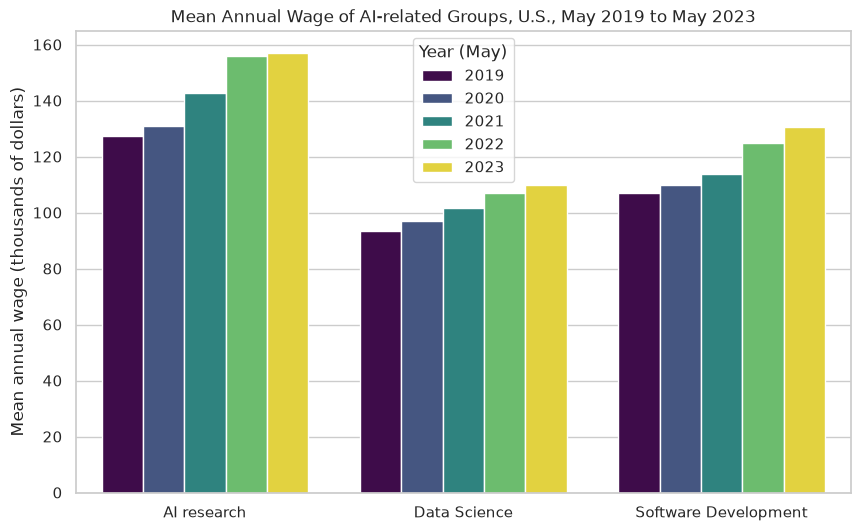

GROUP  AI research  Data Science  Software Development
YEAR                                                  
2019      127460.0       93581.0              106986.0
2020      130890.0       96826.0              109955.0
2021      142650.0      101673.0              113729.0
2022      155880.0      106998.0              124932.0
2023      157160.0      109725.0              130503.0

Change 2019-2023 (%):
GROUP
AI research             23.3
Data Science            17.3
Software Development    22.0
dtype: float64


In [27]:
# Mean wage in thousands of dollars
group_year["MEAN_WAGE_THOUSANDS"] = group_year["MEAN_WAGE"] / 1000

sns.barplot(data=group_year, x="GROUP", y="MEAN_WAGE_THOUSANDS", hue="YEAR", palette="viridis")
plt.title("Mean Annual Wage of AI-related Groups, U.S., May 2019 to May 2023")
plt.xlabel("")
plt.ylabel("Mean annual wage (thousands of dollars)")
plt.legend(title="Year (May)")
plt.show()

# Mean wage of each group, and change from 2019 to 2023 (%)
wage_table = group_year.pivot(index="YEAR", columns="GROUP", values="MEAN_WAGE").round(0)
print(wage_table)
print()
print("Change 2019-2023 (%):")
print(((wage_table.loc[2023] / wage_table.loc[2019] - 1) * 100).round(1))

- **Objective:** To compare how the mean annual wage of each group changed over the five years, and whether the gap between the groups changed.
- **Why this plot:** The chart has two categorical variables (group and year) and one numerical value (wage). A grouped bar chart puts the five years side by side inside each group, so the reader can see the growth inside one group and compare the level of the three groups at the same time. The bars start at zero, so their heights can be compared fairly. The `viridis` palette changes colour step by step, which makes the order of the years clear.
- **Learning:** AI research had the highest mean wage every year, rising from $127,460 to $157,160 (+23.3%). Software Development went from $106,986 to $130,503 (+22.0%), and Data Science had the lowest mean wage every year, from $93,581 to $109,725 (+17.3%). So the gap between AI research and Data Science grew from about $33,900 to $47,400. The biggest jump was for AI research between 2021 and 2022 (from $142,650 to $155,880). These are current dollars, so part of each increase only reflects higher prices, and the real increase is smaller. The Data Science mean is also pulled down because the group mixes well-paid Data Scientists with Operations Research Analysts and Statisticians, and the fast growth of Data Scientists has not been enough to close the gap.

### 5.5 Visualisation 8: Heatmap of the eight occupations, May 2021 to May 2023

The eight occupations of Section 3 all exist from May 2021, so for 2021 to 2023 they can be compared one by one, without the wider groups. The heatmap shows the change in employment of each occupation compared with May 2021.

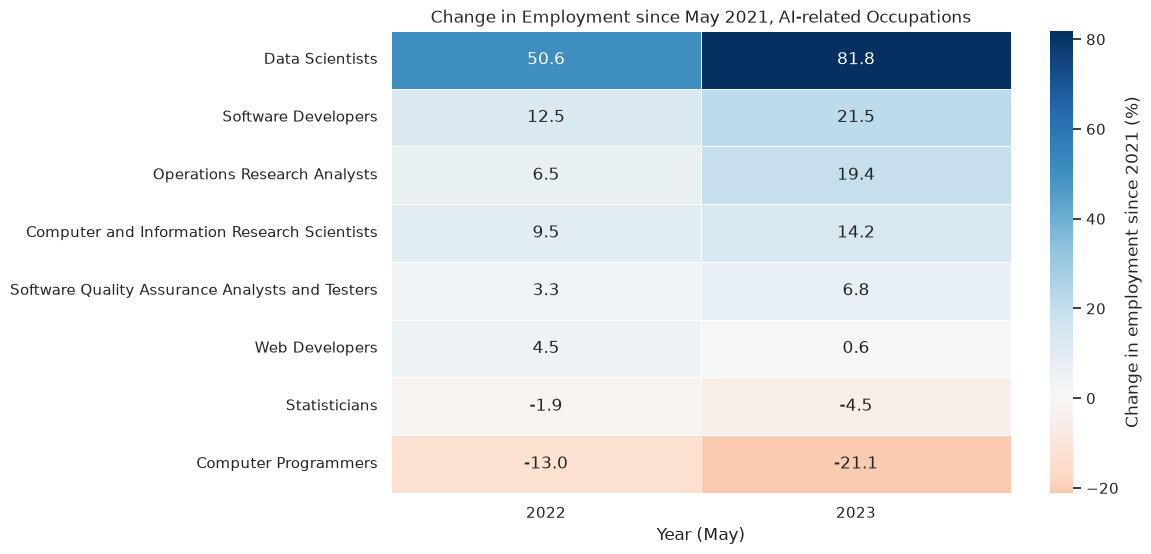

YEAR,2021,2022,2023
OCC_TITLE,,,
Data Scientists,105980.0,159630.0,192710.0
Software Developers,1364180.0,1534790.0,1656880.0
Operations Research Analysts,98700.0,105080.0,117880.0
Computer and Information Research Scientists,30840.0,33780.0,35210.0
Software Quality Assurance Analysts and Testers,190120.0,196420.0,203040.0
Web Developers,84820.0,88620.0,85350.0
Statisticians,31370.0,30780.0,29950.0
Computer Programmers,152610.0,132740.0,120370.0


In [28]:
# The eight occupations of Section 3, in the years where all of them exist
exact = all_years[(all_years["YEAR"] >= 2021) & (all_years["OCC_CODE"].isin(ai_groups.keys()))]

# Employment: one row per occupation, one column per year
exact_emp = exact.pivot(index="OCC_TITLE", columns="YEAR", values="TOT_EMP")

# Change compared with 2021 (%)
exact_change = (exact_emp.div(exact_emp[2021], axis=0) - 1) * 100
# 2021 is the base year (always 0), so only 2022 and 2023 are shown
exact_change = exact_change[[2022, 2023]].sort_values(2023, ascending=False)

sns.heatmap(exact_change, annot=True, fmt=".1f", cmap="RdBu", center=0, linewidths=0.5,
            cbar_kws={"label": "Change in employment since 2021 (%)"})
plt.title("Change in Employment since May 2021, AI-related Occupations")
plt.xlabel("Year (May)")
plt.ylabel("")
plt.show()

# Employment in each year
exact_emp.loc[exact_change.index]

- **Objective:** To find which of the eight AI-related occupations grew and which fell between May 2021 and May 2023.
- **Why this plot:** The data is a small table (eight occupations by two years) with one number in each cell. A heatmap shows the pattern with colour and, with `annot=True`, the exact value in each cell, as in the correlation heatmap of the class tutorial (Ahmed, 2026a). I used a diverging palette (`RdBu`) centred on zero, so growth is blue, a fall is red and no change is white. The rows are sorted by the change in 2023, so the fastest-growing occupation is at the top.
- **Learning:** Data Scientists grew the fastest: +81.8% in two years, from 105,980 to 192,710 workers. Software Developers grew by 21.5%, which is the largest increase in number of workers (292,700 more), followed by Operations Research Analysts (+19.4%) and Computer and Information Research Scientists (+14.2%). At the other end, Computer Programmers fell by 21.1% (from 152,610 to 120,370), Statisticians fell by 4.5% and Web Developers stayed almost the same (+0.6%). So the growth was in jobs that design software and work with data, while the older occupation of "programmer" got smaller. One possible reason is that employers now describe this work as software development instead of programming, but the dataset cannot confirm this.

## 6. Limitations

Some limitations come from my own choices and others from the way BLS collects the OEWS data.

AI employment is a proxy. As explained in Section 3, the SOC system has no AI occupation, so the eight occupations are an approximation. Not every Software Developer works on AI, and some people who do (for example in "Computer Occupations, All Other") are not counted. A different choice of occupations would change the totals, especially for Software Development, which is 84.6% of the group.

Some values are missing or top-coded. BLS does not publish estimates that are not reliable enough or that could identify an employer. Because of this, some states have no value for some occupations: only 42 states have a mean wage for Computer and Information Research Scientists (Visualisation 2), and 18 states have fewer than eight occupations in the map (Visualisation 5), so their values there are a minimum. In addition, wages of $239,200 a year or more are not published as a number (the `#` code, Section 2.2). This mostly affects the 90th percentile of well-paid jobs, which is one reason why the charts use the mean wage and not the percentiles.

OEWS is not designed for trends. BLS says that it "does not encourage the use of OEWS data for time-series analysis" (U.S. Bureau of Labor Statistics, no date). Each set of estimates combines six survey panels collected over three years, so the yearly values overlap and changes appear more slowly than they really happen. The occupation classification also changed: the May 2019 and May 2020 estimates mix the 2010 and 2018 SOC systems, and May 2021 is the first year fully based on the 2018 SOC (U.S. Bureau of Labor Statistics, no date). This is why Section 5 uses slightly wider groups, and why the growth of Data Scientists, a new code in the 2018 SOC, may be partly a change in how jobs are classified. For these reasons, Section 5 shows the general direction of change, not exact yearly growth rates.

Wages are not adjusted for inflation. The wages in Visualisation 7 are in current dollars of each year, so part of the increase from 2019 to 2023 only reflects higher prices.

Only employees are counted. The OEWS survey covers jobs in establishments and "does not cover the self-employed" (U.S. Bureau of Labor Statistics, no date), so freelance developers and data scientists are not in these numbers.

Association is not cause. The relationship in Visualisation 3 (correlation 0.61) shows that states with more Software Developers tend to pay more, but other factors that are not in the data, such as the cost of living, may explain both.

## 7. Summary of findings

1. In May 2023, the eight AI-related occupations employed 2,441,390 people, 1.61% of all U.S. employment. Software Developers alone were 1,656,880 workers, about 68% of the group, while the occupations closest to AI research and statistics were the smallest (Visualisations 1 and 4).
2. Computer and Information Research Scientists were the best paid, with a national mean wage of $157,160, and AI research had a larger share of the wages (1.8%) than of the jobs (1.4%). However, the state where a person works changed the wage a lot: for Software Developers, the mean went from $88,130 in Arkansas to $173,780 in California (Visualisations 2 and 4).
3. AI-related jobs are concentrated in a few states. Washington had 35.1 AI-related jobs per 1,000 jobs, more than twice the U.S. value of 16.1, and only 16 of the 51 areas were above the U.S. value. States with a larger share of Software Developers also tended to pay them more (correlation 0.61) (Visualisations 3 and 5).
4. From May 2019 to May 2023, all three groups grew faster than total employment (+3.4%). Data Science employment more than doubled, Software Development grew by 24.0% and AI research by 14.4%, and the groups kept growing in 2020, when total employment fell (Visualisation 6). Mean wages rose by 17% to 23% in current dollars (Visualisation 7).
5. From 2021 to 2023, Data Scientists grew by 81.8%, while Computer Programmers fell by 21.1% (Visualisation 8).

The data shows that AI-related work in the U.S. is still mostly software development, but the occupations that work with data are the ones growing fastest.

## 8. References

Ahmed, T. (2026a) 'Data visualisation CA-1 type tutorial' [Jupyter notebook], *Data Visualisation and Communication*. CCT College Dublin. 5 October.

Ahmed, T. (2026b) 'EDA using matplotlib' [Jupyter notebook], *Data Visualisation and Communication*. CCT College Dublin. 28 September.

Ahmed, T. (2026c) 'Interactive data visualization with Python Plotly' [Lecture notes], *Data Visualisation and Communication*. CCT College Dublin. 12 October.

Hunter, J.D. (2007) 'Matplotlib: a 2D graphics environment', *Computing in Science & Engineering*, 9(3), pp. 90–95. Available at: https://doi.org/10.1109/MCSE.2007.55 (Accessed: 13 October 2026).

McKinney, W. (2010) 'Data structures for statistical computing in Python', in van der Walt, S. and Millman, J. (eds) *Proceedings of the 9th Python in Science Conference*, pp. 56–61. Available at: https://doi.org/10.25080/Majora-92bf1922-00a (Accessed: 12 October 2026).

Plotly Technologies Inc. (2026) *plotly.py* (Version 6.7.0) [Computer program]. Available at: https://plotly.com/python/ (Accessed: 13 October 2026).

U.S. Bureau of Labor Statistics (no date) *Frequently asked questions: Occupational Employment and Wage Statistics*. Available at: https://www.bls.gov/oes/oes_ques.htm (Accessed: 15 October 2026).

U.S. Bureau of Labor Statistics (2020a) *2018 SOC definitions*. Available at: https://www.bls.gov/soc/2018/soc_2018_definitions.pdf (Accessed: 14 October 2026).

U.S. Bureau of Labor Statistics (2020b) *May 2019 national occupational employment and wage estimates* [Dataset]. Available at: https://www.bls.gov/oes/special-requests/oesm19nat.zip (Accessed: 1 November 2026).

U.S. Bureau of Labor Statistics (2021) *May 2020 national occupational employment and wage estimates* [Dataset]. Available at: https://www.bls.gov/oes/special-requests/oesm20nat.zip (Accessed: 1 November 2026).

U.S. Bureau of Labor Statistics (2022) *May 2021 national occupational employment and wage estimates* [Dataset]. Available at: https://www.bls.gov/oes/special-requests/oesm21nat.zip (Accessed: 1 November 2026).

U.S. Bureau of Labor Statistics (2023) *May 2022 national occupational employment and wage estimates* [Dataset]. Available at: https://www.bls.gov/oes/special-requests/oesm22nat.zip (Accessed: 1 November 2026).

U.S. Bureau of Labor Statistics (2024) *Occupational Employment and Wage Statistics: May 2023 all data* [Dataset]. Available at: https://www.bls.gov/oes/special-requests/oesm23all.zip (Accessed: 4 October 2026).

Waskom, M.L. (2021) 'seaborn: statistical data visualization', *Journal of Open Source Software*, 6(60), 3021. Available at: https://doi.org/10.21105/joss.03021 (Accessed: 3 November 2026).

## 9. Appendix: AI use

_To be completed._